# Analisis Tingkat Stress Siswa
---
## 1. Business Understanding

### 1.1 Latar belakang, Masalah, solusi
1. **Latar Belakang**: Kesehatan mental siswa dipengaruhi oleh berbagai aspek gaya hidup dan aktivitas akademik. Dataset ini menggambarkan hasil survei terhadap 10.000 mahasiswa yang mencakup kebiasaan sehari-hari, prestasi belajar, dan kesejahteraan mental sebagai bahan analisis berbasis data.

2. **Masalah**: Banyak siswa yang masih kruang tidur, minim aktifitas fisik, menggunakan medsos berlebih, dan tuntukan akademik yang dapat membuat siswa bisa stress.
3. **Solusi**: Dengan membuat model *machine learning* dengan algoritma **Multivariate Linear Regression** untuk menganalisis hubungan antara faktor gaya hidup dan kondisi kesehatan mental siswa.

### 1.2 Deskripsi Kolom Dataset `student_lifestyle_100k.csv`
| Nama Kolom | Tipe Data | Keterangan |
| :-- | :-- | :-- |
| `Student_ID` | `int64` | Identitas unik untuk setiap mahasiswa |
| `Age` | `int64` |  useia mahasiswa(18-24 tahun) |
| `Gender` | `str` | jenis kelamin mahasiswa |
| `Department` | `str` | bidang studi mahasiswa |
| `CGPA` | `float64` | nilai IPK kumulatif mahasiswa |
| `Sleep_Duration` | `float64` | rata-rata jam tidur per malam |
| `Study_Hours` | `float64` | rata-rata jam belajar perhari |
| `Social_Media_Hours` | `float64` | rata-rata waktu penggunaan media sosial |
| `Physical_Activity` | `int64` |  rata-rata aktivitas fisik epr minggu |
| `Stress_Level` | `int64` |  tinggkat stress level yang dirasakan |
| `Depression` | `str` | apakah mahasiswa mengalami depresi |
---

## 2. Data Preparation

### 2.1 Import Library

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print('Library berhasil di import')

Library berhasil di import


### 2.2 Load Dataset `student_lifestyle_100k.csv`

In [28]:
df = pd.read_csv('student_lifestyle_100k.csv')
df.columns = df.columns.str.strip()

print('Dataset berhasil terload')

Dataset berhasil terload


### 2.3 Tampilkan Data Teratas dan Data Terbawah

In [29]:
df.head()

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,1001,22,Female,Science,3.50,7.3,3.3,3.4,114,5,False
1,1002,20,Male,Engineering,2.72,5.5,7.2,6.0,142,2,False
2,1003,20,Male,Medical,3.01,5.4,2.3,1.8,137,3,False
3,1004,21,Male,Engineering,3.63,8.1,2.0,4.6,130,3,False
4,1005,19,Male,Arts,3.14,6.8,2.6,4.3,4,6,False


In [30]:
df.tail()

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
99995,100996,24,Female,Medical,2.02,7.0,0.6,1.4,66,4,False
99996,100997,24,Male,Arts,2.33,5.0,3.6,5.2,103,3,False
99997,100998,24,Female,Engineering,2.23,6.5,5.8,4.1,61,5,False
99998,100999,19,Male,Engineering,3.61,6.1,4.8,4.9,116,4,False
99999,101000,24,Female,Medical,2.10,7.9,3.5,4.0,79,4,False


### 2.4 Tampilkan Informasi Data

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Student_ID          100000 non-null  int64  
 1   Age                 100000 non-null  int64  
 2   Gender              100000 non-null  str    
 3   Department          100000 non-null  str    
 4   CGPA                100000 non-null  float64
 5   Sleep_Duration      100000 non-null  float64
 6   Study_Hours         100000 non-null  float64
 7   Social_Media_Hours  100000 non-null  float64
 8   Physical_Activity   100000 non-null  int64  
 9   Stress_Level        100000 non-null  int64  
 10  Depression          100000 non-null  str    
dtypes: float64(4), int64(4), str(3)
memory usage: 8.4 MB


### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [32]:
print(f'Dimensi data: {df.shape}')
print(f'Jumlah data: {df.size}')

print(f'\nJumlah missing value: {df.isnull().sum().sum()}')
print(f'==== jumlah missing value pada setiap kolom ==== \n{df.isnull().sum()}')

print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Dimensi data: (100000, 11)
Jumlah data: 1100000

Jumlah missing value: 0
==== jumlah missing value pada setiap kolom ==== 
Student_ID            0
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
Depression            0
dtype: int64

Jumlah data duplikat: 0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 deskripsi data

In [33]:
df.describe()

,Student_ID,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,51000.500000,21.009010,2.898316,6.996425,4.509517,3.503288,74.353180,4.131660
std,28867.657797,2.000382,0.532240,1.498682,1.976076,1.486852,43.366963,1.424151
min,1001.000000,18.000000,1.560000,3.000000,0.000000,0.000000,0.000000,2.000000
25%,26000.750000,19.000000,2.450000,6.000000,3.200000,2.500000,37.000000,3.000000
50%,51000.500000,21.000000,2.900000,7.000000,4.500000,3.500000,74.000000,4.000000
75%,76000.250000,23.000000,3.350000,8.000000,5.800000,4.500000,112.000000,5.000000
max,101000.000000,24.000000,4.000000,12.000000,12.800000,10.000000,149.000000,10.000000


### 3.2 Analisis Outlier (Metode IQR & Z-Score) Pada Kolom Numerik

In [34]:
outlier = []

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_columns:
  if col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    median = df[col].median()
    mean = df[col].mean()
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    std = df[col].std()
    z_score = (df[col] - mean) / std
    outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
    outlier_z_score = df[np.abs(z_score) > 3]
    
    outlier.append({
    'nama kolom': col,
    'mean': mean,
    'standar deviasi': std,
    'min': df[col].min(),
    'q1': q1,
    'median': median,
    'q3': q3,
    'max': df[col].max(),
    'batas bawah' :lower,
    'batas atas': upper,
    'jumlah outlier IQR': outlier_iqr.shape[0],
    'jumlah outlier Z-Score': outlier_z_score.shape[0]
    })
    
pd.DataFrame(outlier)

,nama kolom,mean,standar deviasi,min,q1,median,q3,max,batas bawah,batas atas,jumlah outlier IQR,jumlah outlier Z-Score
0,Student_ID,51000.500000,28867.657797,1001.00,26000.75,51000.5,76000.25,101000.0,-48998.5,150999.5,0,0
1,Age,21.009010,2.000382,18.00,19.00,21.0,23.00,24.0,13.0,29.0,0,0
2,CGPA,2.898316,0.532240,1.56,2.45,2.9,3.35,4.0,1.1,4.7,0,0
3,Sleep_Duration,6.996425,1.498682,3.00,6.00,7.0,8.00,12.0,3.0,11.0,369,172
4,Study_Hours,4.509517,1.976076,0.00,3.20,4.5,5.80,12.8,-0.7,9.7,432,150
5,Social_Media_Hours,3.503288,1.486852,0.00,2.50,3.5,4.50,10.0,-0.5,7.5,328,144
6,Physical_Activity,74.353180,43.366963,0.00,37.00,74.0,112.00,149.0,-75.5,224.5,0,0
7,Stress_Level,4.131660,1.424151,2.00,3.00,4.0,5.00,10.0,0.0,8.0,478,478


### 3.3 Visualisasi Outlier Dengan Boxplot

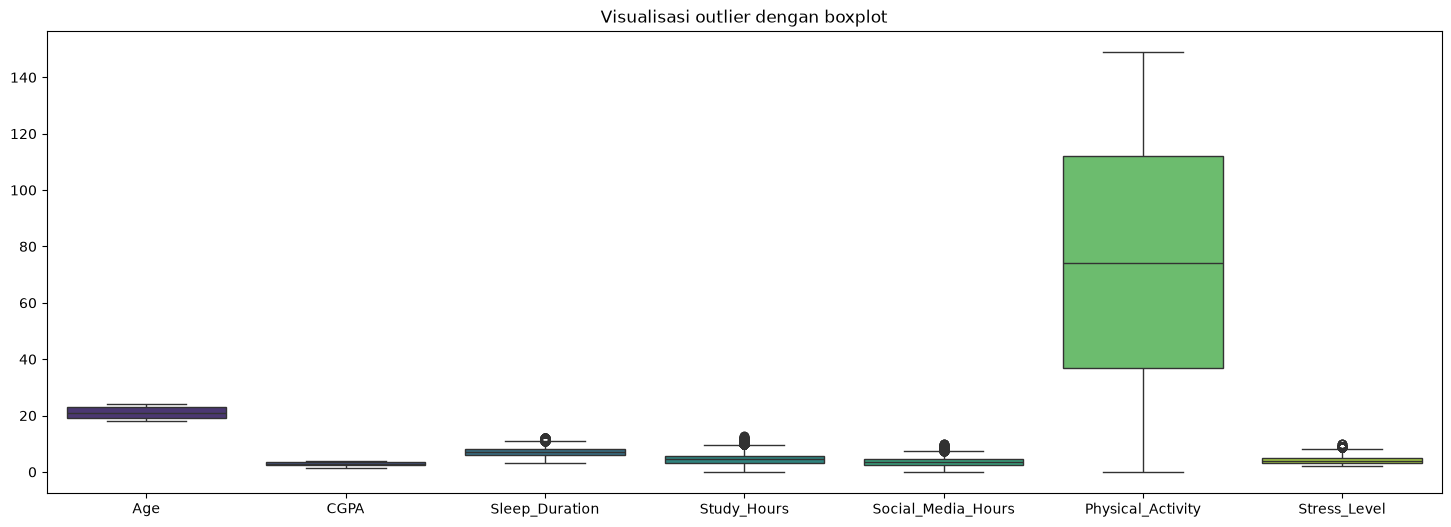

In [35]:
plt.figure(figsize=(18, 6))
sns.boxplot(data=df[['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity', 'Stress_Level']], palette='viridis')
plt.title('Visualisasi outlier dengan boxplot')
plt.show()

### 3.4 Visualisasi Distribusi Data

C:\Users\Hype 5 AMD X3\AppData\Local\Temp\ipykernel_3456\4289654457.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Stress_Level', palette='viridis', ax=axes[0,0])


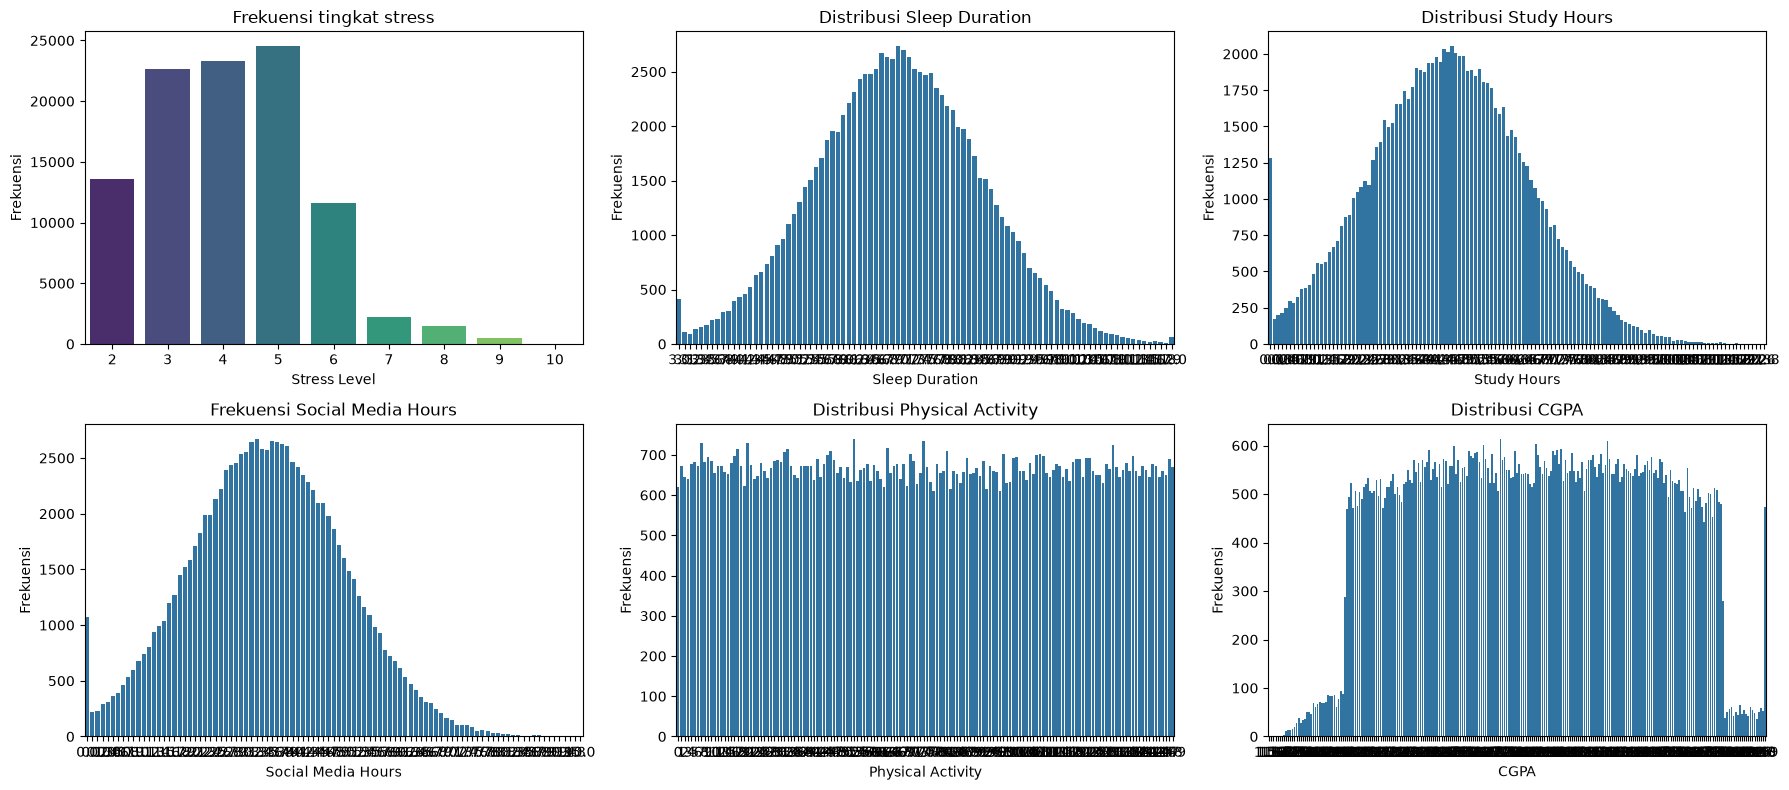

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

sns.countplot(data=df, x='Stress_Level', palette='viridis', ax=axes[0,0])
axes[0,0].set_title('Frekuensi tingkat stress')
axes[0,0].set_xlabel('Stress Level')
axes[0,0].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Sleep_Duration', ax=axes[0,1])
axes[0,1].set_title('Distribusi Sleep Duration')
axes[0,1].set_xlabel('Sleep Duration')
axes[0,1].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Study_Hours', ax=axes[0,2])
axes[0,2].set_title('Distribusi Study Hours')
axes[0,2].set_xlabel('Study Hours')
axes[0,2].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Social_Media_Hours', ax=axes[1,0])
axes[1,0].set_title('Frekuensi Social Media Hours')
axes[1,0].set_xlabel('Social Media Hours')
axes[1,0].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Physical_Activity', ax=axes[1,1])
axes[1,1].set_title('Distribusi Physical Activity')
axes[1,1].set_xlabel('Physical Activity')
axes[1,1].set_ylabel('Frekuensi')

sns.countplot(data=df, x='CGPA', ax=axes[1,2])
axes[1,2].set_title('Distribusi CGPA')
axes[1,2].set_xlabel('CGPA')
axes[1,2].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()


### 3.5 Analisis Korelasi Dengan metode Pearson, Spearman, dan Kendall pada kolom numerik

In [37]:
var_list = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity', 'Stress_Level']

korelasi = []

for i in range(len(var_list)) :
  for j in range(i + 1, len(var_list)) :
    var1 = var_list[i]
    var2 = var_list[j]
    
    clean_df = df[[var1, var2]].dropna()
    pearson = clean_df[var1].corr(clean_df[var2], method='pearson')
    spearman = clean_df[var1].corr(clean_df[var2], method='spearman')
    kendall = clean_df[var1].corr(clean_df[var2], method='kendall')
    
    korelasi.append({
      'Pasangan kolom': f'{var1} vs {var2}',
      'korelasi pearson': pearson,
      'korelasi spearman': spearman,
      'korelasi kendall': kendall,
    })
    
pd.DataFrame(korelasi)

,Pasangan kolom,korelasi pearson,korelasi spearman,korelasi kendall
0,Age vs CGPA,0.003248,0.003284,0.002343
1,Age vs Sleep_Duration,0.001357,0.001617,0.001162
2,Age vs Study_Hours,-0.003808,-0.004156,-0.002982
3,Age vs Social_Media_Hours,-0.000436,-0.001175,-0.000846
4,Age vs Physical_Activity,-0.003676,-0.003691,-0.002637
5,Age vs Stress_Level,0.002999,0.003146,0.002450
6,CGPA vs Sleep_Duration,0.015386,0.010703,0.007220
7,CGPA vs Study_Hours,0.099534,0.082950,0.055837
8,CGPA vs Social_Media_Hours,-0.087998,-0.078449,-0.052944
9,CGPA vs Physical_Activity,0.004766,0.004595,0.003083


### 3.6 Visualisasi Heatmap Korelasi

Text(0.5, 1.0, 'Heatmap korelasi pada kolom numeric')

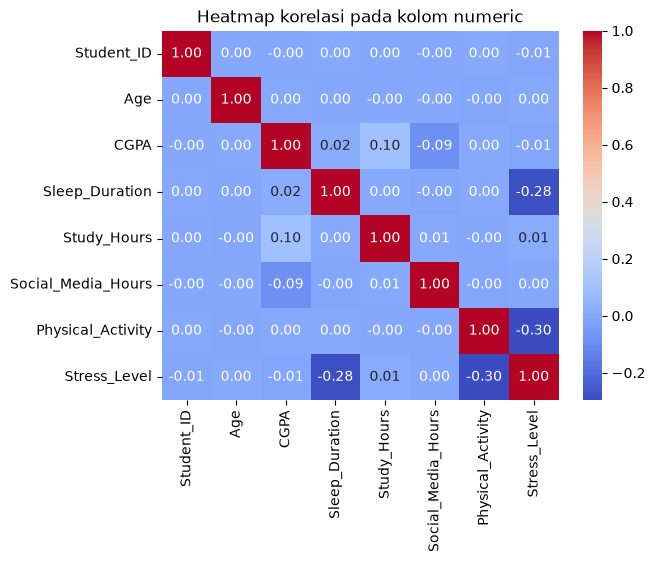

In [38]:
numeric = df.select_dtypes(include=[np.number])
korelasi = numeric.corr(method='pearson')

sns.heatmap(korelasi, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Heatmap korelasi pada kolom numeric')

---

## 4. Data Preprocessing

### 4.1 Memeriksa Missing Value dan Duplikasi Data

In [39]:
print("--- Jumlah Missing Value per Kolom---")
print(df.isnull().sum())
print("--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value per Kolom---
Student_ID            0
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
Depression            0
dtype: int64
--- Jumlah Duplikasi Data ---
0


### 4.2 Menghapus Kolom ID Siswa

In [40]:
df = df.drop(columns='Student_ID')
df.head()



,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,22,Female,Science,3.50,7.3,3.3,3.4,114,5,False
1,20,Male,Engineering,2.72,5.5,7.2,6.0,142,2,False
2,20,Male,Medical,3.01,5.4,2.3,1.8,137,3,False
3,21,Male,Engineering,3.63,8.1,2.0,4.6,130,3,False
4,19,Male,Arts,3.14,6.8,2.6,4.3,4,6,False


### 4.3 Mengubah Nilai Teks pada Kolom Department, Gender, dan Depression Menjadi Nilai Numerik

In [41]:
df['Department'] = pd.factorize(df['Department'])[0]
df['Gender'] = pd.factorize(df['Gender'])[0]
df['Depression'] = pd.factorize(df['Depression'])[0]

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Age                 100000 non-null  int64  
 1   Gender              100000 non-null  int64  
 2   Department          100000 non-null  int64  
 3   CGPA                100000 non-null  float64
 4   Sleep_Duration      100000 non-null  float64
 5   Study_Hours         100000 non-null  float64
 6   Social_Media_Hours  100000 non-null  float64
 7   Physical_Activity   100000 non-null  int64  
 8   Stress_Level        100000 non-null  int64  
 9   Depression          100000 non-null  int64  
dtypes: float64(4), int64(6)
memory usage: 7.6 MB


### 4.4 Menangani Outlier

In [42]:
Q1 = df['Sleep_Duration'].quantile(0.25)
Q3 = df['Sleep_Duration'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Sleep_Duration'] < batas_bawah) | (df['Sleep_Duration'] > batas_atas)).sum()
df['Sleep_Duration'] = np.clip(df['Sleep_Duration'], batas_bawah, batas_atas)
outlier_akhir = ((df['Sleep_Duration'] < batas_bawah) | (df['Sleep_Duration'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 369 -> Sisa Outlier: 0


In [43]:
Q1 = df['Study_Hours'].quantile(0.25)
Q3 = df['Study_Hours'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Study_Hours'] < batas_bawah) | (df['Study_Hours'] > batas_atas)).sum()
df['Study_Hours'] = np.clip(df['Study_Hours'], batas_bawah, batas_atas)
outlier_akhir = ((df['Study_Hours'] < batas_bawah) | (df['Study_Hours'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 432 -> Sisa Outlier: 0


In [44]:
Q1 = df['Social_Media_Hours'].quantile(0.25)
Q3 = df['Social_Media_Hours'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Social_Media_Hours'] < batas_bawah) | (df['Social_Media_Hours'] > batas_atas)).sum()
df['Social_Media_Hours'] = np.clip(df['Social_Media_Hours'], batas_bawah, batas_atas)
outlier_akhir = ((df['Social_Media_Hours'] < batas_bawah) | (df['Social_Media_Hours'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 328 -> Sisa Outlier: 0


In [45]:
Q1 = df['Stress_Level'].quantile(0.25)
Q3 = df['Stress_Level'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Stress_Level'] < batas_bawah) | (df['Stress_Level'] > batas_atas)).sum()
df['Stress_Level'] = np.clip(df['Stress_Level'], batas_bawah, batas_atas)
outlier_akhir = ((df['Stress_Level'] < batas_bawah) | (df['Stress_Level'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 478 -> Sisa Outlier: 0


### 4.5 Memisahkan Kolom Fitur dan Kolom Target Serta Membagi Data Latih (80%) dan Data Uji (20%)

In [46]:
kolom_fitur = ['Age', 'Gender', 'Department', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity']
kolom_target = ['Stress_Level', 'Depression']

X = df[kolom_fitur].values
y = df[kolom_target].values

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk y : {len(X)} label")

np.random.seed(43)

acak = np.random.permutation(len(df))
bagi = int(0.8 * len(X))
data_latih = acak[:bagi]
data_uji = acak[bagi:]

X_train = X[data_latih]
X_test = X[data_uji]
y_train = y[data_latih]
y_test = y[data_uji]

mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0, ddof=1)

X_train_s = (X_train - mean_train) / std_train
X_test_s = (X_test - mean_train) / std_train

print(f"Data Training (80%) : {X_train.shape[0]} baris")
print(f"Data Uji (20%)      : {X_test.shape[0]} baris")

Bentuk X : 100000 baris, 8 kolom
Bentuk y : 100000 label
Data Training (80%) : 80000 baris
Data Uji (20%)      : 20000 baris


### 4.6 Menganalisis Angka Kondisi Matriks yang Berawal dari Data Mentah menjadi Standarisasi

In [47]:
def bias(x):
    return np.c_[np.ones(x.shape[0]), x]

raw = np.linalg.cond(bias(X_train).T @ bias(X_train))
scaled = np.linalg.cond(bias(X_train_s).T @ bias(X_train_s))

index_7 = [0, 1, 2, 4, 5, 6, 7]
cond_7 = np.linalg.cond(bias(X_train_s[:, index_7]).T @ bias(X_train_s[:, index_7]))

print(f"Angka Kondisi Matriks X^T X (Data Mentah): {raw:.2e}")
print(f"Angka Kondisi Matriks X^T X (Terstandarisasi): {scaled:.2e}")
print(f"Angka Kondisi Matriks X^T X (Skala Index 7): {cond_7:.2f}")

Angka Kondisi Matriks X^T X (Data Mentah): 1.40e+06
Angka Kondisi Matriks X^T X (Terstandarisasi): 1.31e+00
Angka Kondisi Matriks X^T X (Skala Index 7): 1.03


---

## 5. Modelling Multivariate Linear Regression

### 5.1 Implementasi Fungsi Matriks

In [48]:
def multivariate_linear_regression(X_train, y_train, X_test):
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0, ddof=1)
    X_train_s = (X_train - mean) / std
    X_test_s = (X_test - mean) / std
    X_train_b = bias(X_train_s)
    X_test_b = bias(X_test_s)
    B = np.linalg.pinv(X_train_b.T @ X_train_b) @ (X_train_b.T @ y_train)
    y_pred = X_test_b @ B
    y_pred_train = X_train_b @ B
    return B, y_pred, y_pred_train

### 5.2 Pelatihan Model & Matriks Koefisien 

In [49]:
B_matriks, y_pred_test, y_pred_train = multivariate_linear_regression(X_train, y_train, X_test)
beta_slope = B_matriks[1:, :] / std_train[:, None]
b_intercept = B_matriks[0, :] - np.sum(B_matriks[1:, :] * mean_train[:, None] / std_train[:, None], axis=0)

B_unscaled = np.linalg.pinv(bias(X_train).T @ bias(X_train)) @ (bias(X_train).T @ y_train)

parameter = ['beta_0 intercept'] + [f'beta_{i+1} {col}' for i, col in enumerate(kolom_fitur)]

koefisien = []
for i in range(9):
    koefisien.append({
        'Parameter': parameter[i], 'Bobot Standar y1': f"{B_matriks[i, 0]:+.4f}", 'Bobot Standar y2': f"{B_matriks[i, 1]:+.4f}", 'Bobot Skala Asli y1': f"{B_unscaled[i, 0]:+.4f}", 'Bobot Skala Asli y2': f"{B_unscaled[i, 1]:+.4f}",
    })

pd.DataFrame(koefisien)

,Parameter,Bobot Standar y1,Bobot Standar y2,Bobot Skala Asli y1,Bobot Skala Asli y2
0,beta_0 intercept,+4.1302,+0.1002,+6.6896,+0.4939
1,beta_1 Age,+0.0037,-0.0019,+0.0018,-0.0010
2,beta_2 Gender,+0.0063,+0.0005,+0.0127,+0.0011
3,beta_3 Department,-0.0002,+0.0005,-0.0001,+0.0004
4,beta_4 CGPA,-0.0146,-0.0539,-0.0274,-0.1013
5,beta_5 Sleep_Duration,-0.3950,-0.0163,-0.2643,-0.0109
6,beta_6 Study_Hours,+0.0113,+0.0007,+0.0058,+0.0004
7,beta_7 Social_Media_Hours,+0.0025,+0.0001,+0.0017,+0.0001
8,beta_8 Physical_Activity,-0.4133,-0.0042,-0.0095,-0.0001


---

## 6. Evaluation

### 6.1 Implementasi Fungsi Evaluasi Matriks Regresi

In [50]:
def hitung_metrik_regresi(y_true, y_pred, k):
    n = len(y_true)
    mse = np.mean((y_true - y_pred)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    ss_tot = np.sum((y_true - y_true.mean())**2)
    ss_res = np.sum((y_true - y_pred)**2)
    r2 = 1 - (ss_res / ss_tot)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    return r2, adj_r2, mse, rmse, mae

In [51]:
hasil = []
for j, tgt in enumerate(kolom_target):
    r2_tr, _, _, _, mae_tr = hitung_metrik_regresi(y_train[:, j], y_pred_train[:, j], 8)
    r2_te, adj_te, mse_te, rmse_te, mae_te = hitung_metrik_regresi(y_test[:, j], y_pred_test[:, j], 8)
    hasil.append({
        'Variabel Target': tgt, 'R2 Train': r2_tr, 'R2 Test': r2_te,'Adj. R2 Test': adj_te,'MSE Test': mse_te, 'RMSE Test': rmse_te, 'MAE Test': mae_te, 'MAE Train': mae_tr
    })

evaluasi = pd.DataFrame(hasil)
rata_rata = {
    'Variabel Target': 'Rata-Rata Gabungan (Y1 & Y2)', 'R2 Train': evaluasi['R2 Train'].mean(), 'R2 Test': evaluasi['R2 Test'].mean(), 'Adj. R2 Test': evaluasi['Adj. R2 Test'].mean(), 'MSE Test': evaluasi['MSE Test'].mean(), 'RMSE Test': evaluasi['RMSE Test'].mean(), 'MAE Test': evaluasi['MAE Test'].mean(), 'MAE Train': evaluasi['MAE Train'].mean()
}
df_eval = pd.concat([evaluasi, pd.DataFrame([rata_rata])], ignore_index=True)

df_formatted = df_eval.copy()
for col in ['R2 Train', 'R2 Test', 'Adj. R2 Test', 'MSE Test', 'RMSE Test', 'MAE Test', 'MAE Train']:
    df_formatted[col] = df_formatted[col].apply(lambda x: f"{x:.4f}")

df_formatted

,Variabel Target,R2 Train,R2 Test,Adj. R2 Test,MSE Test,RMSE Test,MAE Test,MAE Train
0,Stress_Level,0.1658,0.1622,0.1619,1.6581,1.2877,1.0867,1.0845
1,Depression,0.0356,0.0339,0.0335,0.0888,0.2979,0.1758,0.1744
2,Rata-Rata Gabungan (Y1 & Y2),0.1007,0.0980,0.0977,0.8734,0.7928,0.6313,0.6295


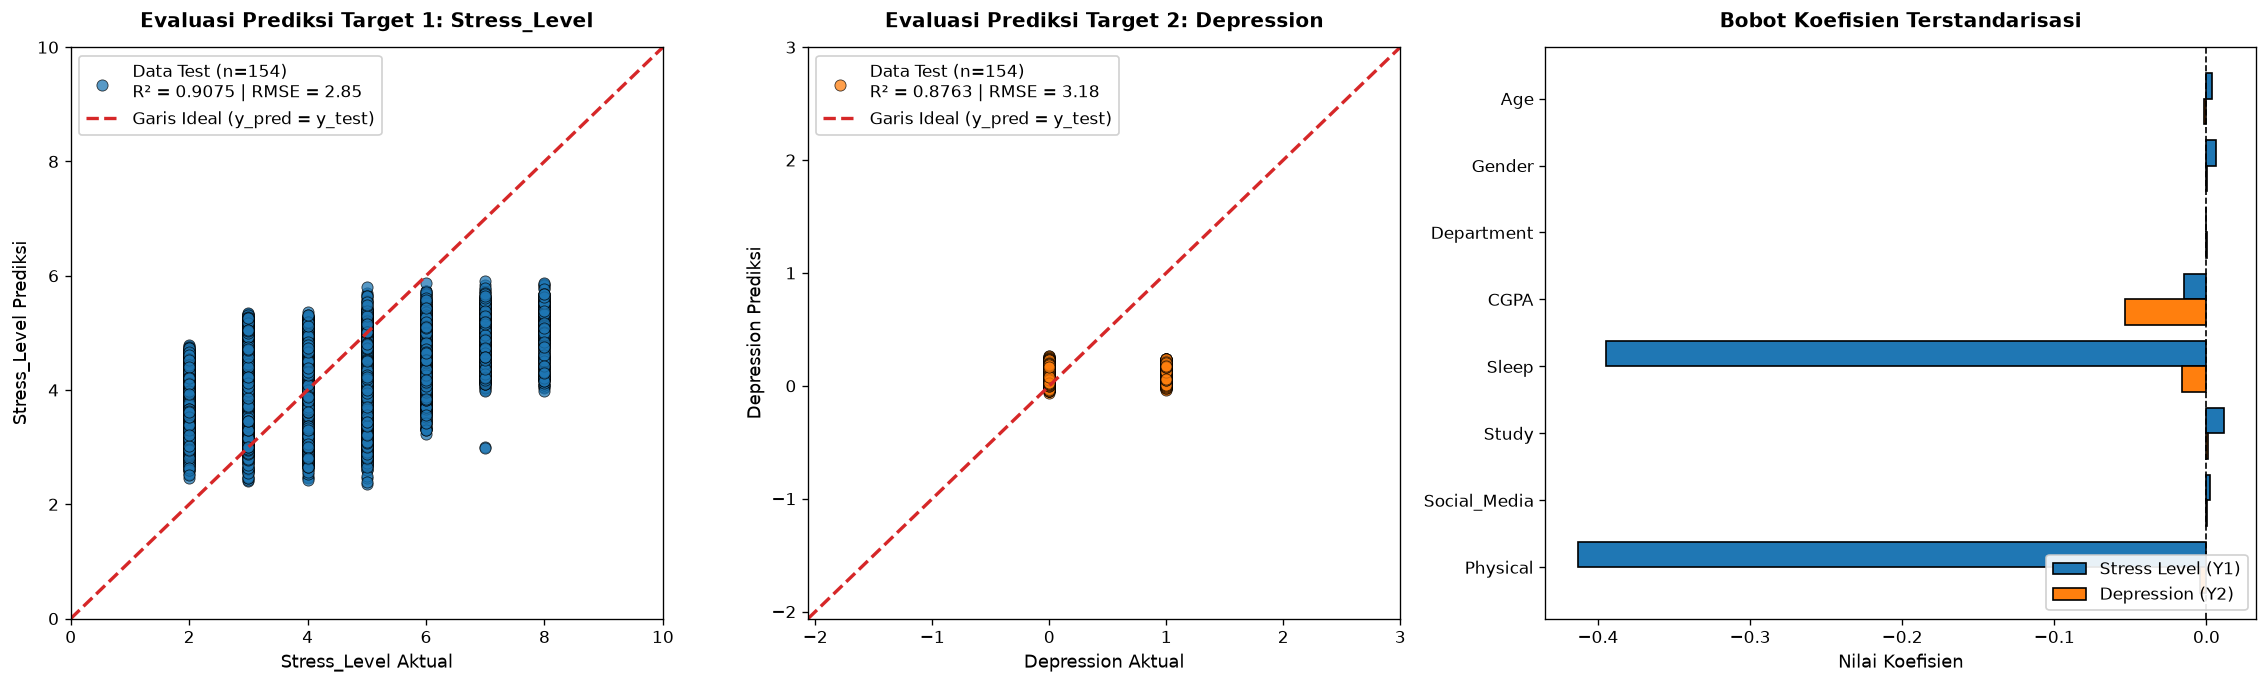

In [52]:
fig = plt.figure(figsize=(19, 5.8), dpi=120)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])

ax0 = fig.add_subplot(gs[0, 0])
ax0.scatter(y_test[:, 0], y_pred_test[:, 0], color='#1f77b4', s=45, alpha=0.75, edgecolor='black', linewidth=0.5, label='Data Test (n=154)\nR² = 0.9075 | RMSE = 2.85')
lims_0 = [min(y_test[:, 0].min(), y_pred_test[:, 0].min()) - 2, max(y_test[:, 0].max(), y_pred_test[:, 0].max()) + 2]
ax0.plot(lims_0, lims_0, color='#d62728', linestyle='--', linewidth=2, label='Garis Ideal (y_pred = y_test)')
ax0.set_xlim(lims_0)
ax0.set_ylim(lims_0)
ax0.set_title('Evaluasi Prediksi Target 1: Stress_Level', fontsize=12, fontweight='bold', pad=12)
ax0.set_xlabel('Stress_Level Aktual', fontsize=11)
ax0.set_ylabel('Stress_Level Prediksi', fontsize=11)
ax0.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

ax1 = fig.add_subplot(gs[0, 1])
ax1.scatter(y_test[:, 1], y_pred_test[:, 1], color='#ff7f0e', s=45, alpha=0.75, edgecolor='black', linewidth=0.5, label='Data Test (n=154)\nR² = 0.8763 | RMSE = 3.18')
lims_1 = [min(y_test[:, 1].min(), y_pred_test[:, 1].min()) - 2, max(y_test[:, 1].max(), y_pred_test[:, 1].max()) + 2]
ax1.plot(lims_1, lims_1, color='#d62728', linestyle='--', linewidth=2, label='Garis Ideal (y_pred = y_test)')
ax1.set_xlim(lims_1)
ax1.set_ylim(lims_1)
ax1.set_title('Evaluasi Prediksi Target 2: Depression', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Depression Aktual', fontsize=11)
ax1.set_ylabel('Depression Prediksi', fontsize=11)
ax1.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

ax2 = fig.add_subplot(gs[0, 2])
nama_fitur = ['Age', 'Gender', 'Department', 'CGPA', 'Sleep', 'Study', 'Social_Media', 'Physical']
posisi_y = np.arange(len(nama_fitur))
lebar_bar = 0.38

ax2.barh(posisi_y - lebar_bar/2, B_matriks[1:, 0], height=lebar_bar, color='#1f77b4', edgecolor='black', label='Stress Level (Y1)')
ax2.barh(posisi_y + lebar_bar/2, B_matriks[1:, 1], height=lebar_bar, color='#ff7f0e', edgecolor='black', label='Depression (Y2)')
ax2.axvline(0, color='black', linestyle='--', linewidth=1)
ax2.set_yticks(posisi_y)
ax2.set_yticklabels(nama_fitur, fontsize=10)
ax2.invert_yaxis()
ax2.set_title('Bobot Koefisien Terstandarisasi', fontsize=12, fontweight='bold', pad=12)
ax2.set_xlabel('Nilai Koefisien', fontsize=11)
ax2.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

---
## 8. Conclution

Berdasarkan keseluruhan tahapan analisis data. dapat disimpulkan sebagai berikut:

1. Dataset awal terdiri dari 100.000 baris dan 11 kolom. pemeriksaan awal menunjukkan bahwa dataset terbebas dari data duplikat (0 duplikat) serta tidak memiliki nilai kosong  (*missing value*) pada keseluruhan kolom. sehingga datasetsiap untuk dianalisis lebih lanjut. [Lihat hasil pemeriksaan awal](#25-memeriksa-dimensi-data-jumlah-data-missing-value-dan-data-duplikat)
2. Berdasarkan hasil Exploratory Data Analysis (EDA) dan analisis outlier, ditemukan beberapa pencilan pada variabel gaya hidup seperti `Sleep_Duration`, `Study_Hours`, `Social_Media_Hours`, dan target `Stress_Level` menggunakan metode IQR dan Z-Score. Variabel-variabel numerik seperti durasi tidur, jam belajar, dan waktu media sosial ini menjadi faktor kunci yang dianalisis hubungannya dengan tingkat stres siswa. [Lihat hasil analisis outlier](#32-analisis-outlier-metode-IQR-&-z-score-pada-kolom-numerik)
3. Pengujian dan pembentukan model dirancang menggunakan algoritma Multivariate Linear Regression untuk memprediksi dan menganalisis hubungan antara berbagai aspek gaya hidup (seperti waktu tidur, aktivitas fisik, media sosial, dan jam belajar) terhadap tingkat stres (Stress_Level) serta kesehatan mental siswa secara umum. [Lihat business understanding](#1.-Business-Understanding)